# NASA GLOBE-Based Geospatial Misinformation Monitor
## Week 2 Demo

**Research question:** Can location-based environmental claims (e.g. wildfire reports) be verified against real NASA satellite observations instead of relying on text classification alone?

This notebook walks through the Week 2 baseline pipeline:

`Claim -> spaCy NER -> Geocoding -> NASA FIRMS -> Spatial/temporal comparison -> Evidence result`

The claims used here are **synthetic demo data**, not real social media posts.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT / "src"))
DATA_DIR = PROJECT_ROOT / "data"

## Headline Demonstration — One Claim, End to End

A ~1 minute trace of a single wildfire claim through the full pipeline:

`claim text -> spaCy location -> geocoded location -> lat/lon -> FIRMS query region -> nearest VIIRS detection -> distance (km) -> evidence result`

No results are fabricated. If FIRMS returns no fire for the queried region and date, the result is `NO_MATCH` or `INSUFFICIENT_EVIDENCE`.

In [2]:
import ner
import geocode
import firms
import verify

DEMO_CLAIM_ID = 4

claims = pd.read_csv(DATA_DIR / "wildfire_claims.csv")
claim = claims[claims["claim_id"] == DEMO_CLAIM_ID].iloc[0]

nlp = ner.load_model()
entities = ner.extract_locations(nlp(claim["text"]))
extracted = ner.pick_location(entities)

coords = geocode.geocode(extracted)
lat, lon = coords["latitude"], coords["longitude"]
bbox = firms.build_bbox(lat, lon)

detections = firms.fetch_detections(lat, lon, claim["date"]) if firms.get_map_key() else None
result = verify.verify(lat, lon, detections)

print(f"1. Claim text        : {claim['text']}")
print(f"   Claim date        : {claim['date']}")
print(f"2. spaCy location    : {extracted}   (all entities: {entities})")
print(f"3. Geocoded location : {coords['display_name']}")
print(f"4. Latitude/Longitude: {lat:.4f}, {lon:.4f}")
print(f"5. FIRMS query region: bbox {bbox}  |  source {firms.SOURCE}")

if detections is None:
    print("6. FIRMS detections  : skipped (no FIRMS_MAP_KEY set)")
else:
    print(f"6. FIRMS detections  : {len(detections)} returned for this region/date")

if result["nearest_detection_km"] is not None:
    print(f"7. Nearest VIIRS fire: {result['nearest_detection_km']} km from the claim location")
else:
    print("7. Nearest VIIRS fire: none within the queried region/date")

print(f"8. Threshold         : {verify.DISTANCE_THRESHOLD_KM} km  |  source: {result['evidence_source']}")
print(f"\n   EVIDENCE RESULT   : {result['verdict']}")

notes = {
    "SUPPORTED": "A VIIRS detection lies within the threshold, so the satellite record is consistent with the claim.",
    "NO_MATCH": "No VIIRS detection lies within the threshold. This does NOT prove the claim is false - it only means this evidence source does not support it (data gaps, timing, or a fire too small to detect are all possible).",
    "INSUFFICIENT_EVIDENCE": "No usable satellite data for this location/date (no FIRMS key, or the date is outside the VIIRS near-real-time window), so no judgement can be made.",
}
print(f"   Interpretation    : {notes[result['verdict']]}")

1. Claim text        : Large fire reported near Lahaina
   Claim date        : 2023-08-08
2. spaCy location    : Lahaina   (all entities: ['Lahaina'])
3. Geocoded location : Lahaina, Maui County, Hawaii, United States
4. Latitude/Longitude: 20.8739, -156.6777
5. FIRMS query region: bbox -156.927678,20.6238769,-156.427678,21.1238769  |  source VIIRS_NOAA20_NRT
6. FIRMS detections  : 0 returned for this region/date
7. Nearest VIIRS fire: none within the queried region/date
8. Threshold         : 25.0 km  |  source: NASA FIRMS VIIRS

   EVIDENCE RESULT   : NO_MATCH
   Interpretation    : No VIIRS detection lies within the threshold. This does NOT prove the claim is false - it only means this evidence source does not support it (data gaps, timing, or a fire too small to detect are all possible).


**Note on this demo claim:** it uses `VIIRS_NOAA20_NRT`, which only retains roughly the last two months of detections. The demo dates in the synthetic set are older, so a `NO_MATCH` here reflects a data-availability limit, not a false claim. To observe a `SUPPORTED` result, point the pipeline at a recent date (within the NRT window) near an actively burning region.

## 1. Load the wildfire claims dataset

In [3]:
claims = pd.read_csv(DATA_DIR / "wildfire_claims.csv")
print(f"Total claims: {len(claims)}")
claims.head()

Total claims: 30


,claim_id,text,date,expected_location,category
0,1,Wildfire spreading near Malibu tonight,2025-01-07,"Malibu, California",wildfire
1,2,Smoke is covering Los Angeles after the fire,2025-01-08,Los Angeles,smoke
2,3,Residents are evacuating near Paradise California,2018-11-08,"Paradise, California",evacuation
3,4,Large fire reported near Lahaina,2023-08-08,Lahaina,wildfire
4,5,Wildfire activity reported across Northern Cal...,2020-09-09,Northern California,wildfire


## 2. Run spaCy NER

Extract geographic entities (GPE / LOC / FAC) and compare against the expected location.

In [4]:
import ner

ner_results = ner.run_ner()
ner_results.head(10)

,claim_id,text,expected_location,extracted_location,all_location_entities,ner_match
0,1,Wildfire spreading near Malibu tonight,"Malibu, California",Malibu,Malibu,partial
1,2,Smoke is covering Los Angeles after the fire,Los Angeles,Los Angeles,Los Angeles,correct
2,3,Residents are evacuating near Paradise California,"Paradise, California",Paradise California,Paradise California,correct
3,4,Large fire reported near Lahaina,Lahaina,Lahaina,Lahaina,correct
4,5,Wildfire activity reported across Northern Cal...,Northern California,Northern California,Northern California,correct
5,6,Thick smoke blanketed Maui this morning,"Maui, Hawaii",,,missing
6,7,Burned area now stretches for miles outside Pa...,"Paradise, California",Paradise,Paradise,partial
7,8,Evacuation orders issued for parts of Orange C...,Orange County,Orange County,Orange County,correct
8,9,New York skyline turned orange from distant wi...,New York,New York,New York,correct
9,10,Firefighters battling flames in the hills abov...,Los Angeles,Los Angeles,Los Angeles,correct


## 3. Examples of each NER outcome

In [5]:
for label in ["correct", "partial", "incorrect", "missing"]:
    subset = ner_results[ner_results["ner_match"] == label]
    print(f"=== {label.upper()} ({len(subset)}) ===")
    if not subset.empty:
        print(subset[["text", "expected_location", "extracted_location"]].head(2).to_string(index=False))
    print()

=== CORRECT (16) ===
                                             text    expected_location  extracted_location
     Smoke is covering Los Angeles after the fire          Los Angeles         Los Angeles
Residents are evacuating near Paradise California Paradise, California Paradise California

=== PARTIAL (7) ===
                                                text    expected_location extracted_location
              Wildfire spreading near Malibu tonight   Malibu, California             Malibu
Burned area now stretches for miles outside Paradise Paradise, California           Paradise

=== INCORRECT (1) ===
                                                 text expected_location extracted_location
Smoke from Canadian wildfires blankets the East Coast            Canada     the East Coast

=== MISSING (6) ===
                                                text expected_location extracted_location
             Thick smoke blanketed Maui this morning      Maui, Hawaii                   


## 4. NER result counts

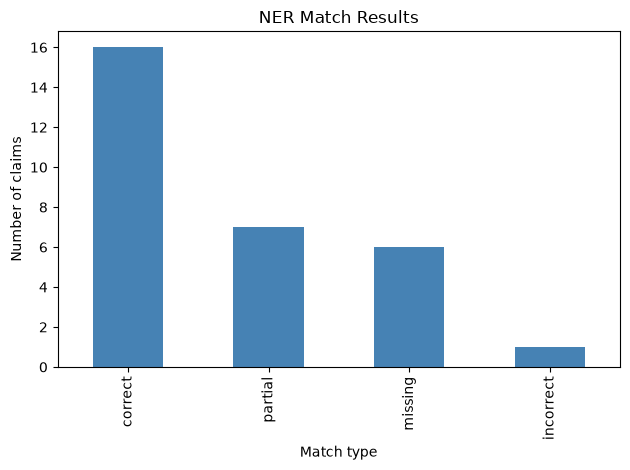

In [6]:
counts = ner_results["ner_match"].value_counts()
counts.plot(kind="bar", color="steelblue")
plt.title("NER Match Results")
plt.xlabel("Match type")
plt.ylabel("Number of claims")
plt.tight_layout()
plt.show()

## NER Evaluation (baseline, no correction rules)

Each claim's extracted location is compared against the `expected_location` column. Strings are normalized (lowercased, commas dropped) before comparison, and labeled:

- **correct** — normalized strings match exactly
- **partial** — one normalized string contains the other (e.g. `Malibu` vs `Malibu, California`): right place, coarser granularity
- **incorrect** — a location was extracted but does not overlap the expected one
- **missing** — spaCy found no location entity

Two headline numbers:

- **Strict accuracy = correct / total** — exact matches only
- **Lenient success = (correct + partial) / total** — counts partials as usable, since they still identify the correct place

These are raw baseline numbers. No post-hoc rules are applied to fix spaCy's output, so the figures can be compared against future model changes.

In [7]:
import evaluate

eval_summary = evaluate.evaluate_ner()
strict = eval_summary.loc[eval_summary["outcome"] == "strict_accuracy", "percentage"].iloc[0]
lenient = eval_summary.loc[eval_summary["outcome"] == "lenient_success", "percentage"].iloc[0]

print(f"Strict accuracy (exact only)      : {strict}%")
print(f"Lenient success (exact + partial) : {lenient}%")
print("Saved to data/ner_evaluation.csv")
eval_summary

Strict accuracy (exact only)      : 53.3%
Lenient success (exact + partial) : 76.7%
Saved to data/ner_evaluation.csv


,outcome,count,percentage
0,correct,16,53.3
1,partial,7,23.3
2,incorrect,1,3.3
3,missing,6,20.0
4,strict_accuracy,16,53.3
5,lenient_success,23,76.7


In [8]:
cols = ["text", "expected_location", "extracted_location", "ner_match"]

worked = ner_results[ner_results["ner_match"] == "correct"].head(5)
print("5 cases where spaCy worked (exact match):")
print(worked[cols].to_string(index=False))

priority = {"incorrect": 0, "missing": 1, "partial": 2}
struggle = ner_results[ner_results["ner_match"] != "correct"].copy()
struggle["_p"] = struggle["ner_match"].map(priority)
struggle = struggle.sort_values(["_p", "claim_id"]).head(5)
print("\n5 cases where spaCy struggled:")
print(struggle[cols].to_string(index=False))

ambiguous = ["Paradise", "Orange County", "Northern California", "Maui", "Los Angeles"]
pattern = "|".join(ambiguous)
focus = ner_results[
    ner_results["text"].str.contains(pattern, case=False)
    | ner_results["expected_location"].str.contains(pattern, case=False)
]
print("\nAmbiguous geographic names of interest:")
print(focus[cols].to_string(index=False))

5 cases where spaCy worked (exact match):
                                                 text    expected_location  extracted_location ner_match
         Smoke is covering Los Angeles after the fire          Los Angeles         Los Angeles   correct
    Residents are evacuating near Paradise California Paradise, California Paradise California   correct
                     Large fire reported near Lahaina              Lahaina             Lahaina   correct
Wildfire activity reported across Northern California  Northern California Northern California   correct
  Evacuation orders issued for parts of Orange County        Orange County       Orange County   correct

5 cases where spaCy struggled:
                                                 text  expected_location extracted_location ner_match
Smoke from Canadian wildfires blankets the East Coast             Canada     the East Coast incorrect
              Thick smoke blanketed Maui this morning       Maui, Hawaii                    

**Ambiguous-name observations:** `Northern California` and `Orange County` are extracted correctly as entities, but `Maui` is sometimes missed when it appears mid-sentence (`Thick smoke blanketed Maui this morning`), and `Paradise` is only ever matched partially because spaCy returns the bare city name without the state. The abbreviation `LA` is a known hard case but is not yet in this corpus, so it is left for a future round rather than patched in. None of these are corrected here, by design.

## Location Resolution Experiment (A / B / C)

Compares three geographic-extraction methods on the same claims:

- **A** — baseline spaCy NER
- **B** — spaCy + Nominatim resolution (plain best match)
- **C** — spaCy + contextual resolver (candidate ranking)

Reported per method: exact / partial / incorrect / missing counts, exact-match rate, and geocoding success rate. The baseline is preserved separately so the comparison is honest — **including cases where resolution does worse**, which it does here.

In [9]:
import location_experiment

location_summary = location_experiment.run_experiment()
location_summary

,method,correct,partial,incorrect,missing,exact_match_rate,geocoding_success_rate
0,A_spacy_baseline,16,7,1,6,53.3,NaN
1,B_spacy_nominatim,13,7,4,6,43.3,80.0
2,C_contextual_resolver,13,7,4,6,43.3,80.0


## 5. Geocode extracted locations

Uses OpenStreetMap / Nominatim with an in-memory cache and a short delay between requests.

In [10]:
import geocode

unique_locations = sorted(set(loc for loc in ner_results["extracted_location"] if loc))
geo_rows = []
for loc in unique_locations:
    coords = geocode.geocode(loc)
    if coords:
        geo_rows.append({"location": loc, **coords})

pd.DataFrame(geo_rows)

,location,latitude,longitude,display_name
0,Canada,61.066692,-107.991707,Canada
1,Lahaina,20.873877,-156.677678,"Lahaina, Maui County, Hawaii, United States"
2,Los Angeles,34.053692,-118.242768,"Los Angeles, Los Angeles County, California, U..."
3,Malibu,34.035591,-118.689423,"Malibu, Los Angeles County, California, 90265,..."
4,Maui,20.802957,-156.310683,"Maui, Maui County, Hawaii, United States"
5,New York,40.712728,-74.006015,"New York, United States"
6,New York City,40.712728,-74.006015,"New York, United States"
7,Northern California,35.134513,33.922586,"California, Nane Sokak, Sakarya, Karakol Mahal..."
8,Orange County,33.750631,-117.872231,"Orange County, California, United States"
9,Paradise,36.072430,-115.147476,"Paradise, Clark County, Nevada, United States"


## 6. NASA FIRMS evidence (if an API key is available)

Requires the `FIRMS_MAP_KEY` environment variable. If it is not set, this step is skipped.

In [11]:
import firms

if firms.get_map_key():
    sample = geocode.geocode("Malibu, California")
    detections = firms.fetch_detections(sample["latitude"], sample["longitude"], "2025-01-07")
    print(f"Detections returned: {0 if detections is None else len(detections)}")
    if detections:
        display(pd.DataFrame(detections).head())
else:
    print("FIRMS_MAP_KEY not set - FIRMS verification skipped.")

Detections returned: 0


## MODIS vs VIIRS Evidence Comparison

The same case study (`Lahaina`, from the headline demo above) is queried against three FIRMS sensors over the identical bounding box and date, recording detections found, nearest detection, and average FRP. Missing data is left blank rather than filled in.

**Why sensor resolution matters for misinformation verification.** MODIS senses active fire at ~1 km, while VIIRS (NOAA-20 / NOAA-21) senses at ~375 m. The finer VIIRS footprint can pick up smaller or earlier-stage fires that MODIS misses, so a claim could look like `NO_MATCH` under MODIS yet `SUPPORTED` under VIIRS. For grounding environmental claims, the choice of sensor sets a floor on how small a fire can be before "no detection" stops being meaningful evidence — which is exactly why absence of a detection should not be read as proof a claim is false.

In [12]:
import sensor_comparison

if firms.get_map_key():
    sensor_table = sensor_comparison.compare_sensors(lat, lon, claim["date"])
    display(sensor_table)
else:
    print("FIRMS_MAP_KEY not set - sensor comparison skipped.")

,sensor,spatial_resolution,detections_found,nearest_detection_km,average_frp,date_coverage
0,MODIS,1 km,0,None,None,None
1,VIIRS NOAA-20,375 m,0,None,None,None
2,VIIRS NOAA-21,375 m,0,None,None,None


## Threshold Sensitivity Experiment

The spatial match threshold is a research **design choice**, not a fixed truth. The same location is evaluated at 5, 10, 25, and 50 km. The synthetic claim's historical date returns no NRT detections (counts are 0, which is honest, not a bug); a recent California example on live FIRMS data shows how the match count grows with the search radius.

In [13]:
import threshold_experiment as te

print("Synthetic claim (Lahaina, 2023-08-08) - outside the NRT window:")
display(te.threshold_sweep(lat, lon, claim["date"]))

if firms.get_map_key():
    center, recent, used_date = te.recent_region_sweep()
    print(f"\nRecent California FIRMS data ({used_date}), densest fire center {center}:")
    display(recent if recent is not None else "No recent California detections for this date.")
else:
    print("\nFIRMS_MAP_KEY not set - recent-data sweep skipped.")

Synthetic claim (Lahaina, 2023-08-08) - outside the NRT window:


,threshold_km,matches_within_threshold
0,5,0
1,10,0
2,25,0
3,50,0



Recent California FIRMS data (2026-10-11), densest fire center (38.81799, -121.88698):


,threshold_km,matches_within_threshold
0,5,2
1,10,2
2,25,3
3,50,6


## Structured Evidence Records & Confidence Score

Instead of a bare verdict, each claim produces a structured evidence record with a transparent confidence score in `[0, 1]` (formula documented in `src/evidence.py`). The score is a prototype confidence indicator, **not** scientific certainty, and no claim is labelled misinformation merely because no detection exists. Verdicts are conservative: `SUPPORTED`, `INSUFFICIENT_EVIDENCE`, or `LOCATION_AMBIGUOUS`.

In [14]:
import evidence

evidence_records = evidence.build_records()
print("Verdict counts:")
print(evidence_records["verdict"].value_counts())
evidence_records[["claim_id", "claim_text", "normalized_location", "evidence_score", "verdict"]].head(10)

Verdict counts:
verdict
INSUFFICIENT_EVIDENCE    27
LOCATION_AMBIGUOUS        3
Name: count, dtype: int64


,claim_id,claim_text,normalized_location,evidence_score,verdict
0,1,Wildfire spreading near Malibu tonight,"Malibu, Los Angeles County, California, 90265,...",0.120,INSUFFICIENT_EVIDENCE
1,2,Smoke is covering Los Angeles after the fire,"Los Angeles, Los Angeles County, California, U...",0.158,INSUFFICIENT_EVIDENCE
2,3,Residents are evacuating near Paradise California,"Paradise, Butte County, California, 95969, Uni...",0.116,INSUFFICIENT_EVIDENCE
3,4,Large fire reported near Lahaina,"Lahaina, Maui County, Hawaii, United States",0.130,INSUFFICIENT_EVIDENCE
4,5,Wildfire activity reported across Northern Cal...,"California Pets Shop, طريق 304, سوق واقف, مدين...",0.000,LOCATION_AMBIGUOUS
5,6,Thick smoke blanketed Maui this morning,,0.000,INSUFFICIENT_EVIDENCE
6,7,Burned area now stretches for miles outside Pa...,"Paradise, Clark County, Nevada, United States",0.120,INSUFFICIENT_EVIDENCE
7,8,Evacuation orders issued for parts of Orange C...,"Orange County, California, United States",0.130,INSUFFICIENT_EVIDENCE
8,9,New York skyline turned orange from distant wi...,"New York, United States",0.134,INSUFFICIENT_EVIDENCE
9,10,Firefighters battling flames in the hills abov...,"Los Angeles, Los Angeles County, California, U...",0.158,INSUFFICIENT_EVIDENCE


## 7. Final verification results

Run the full pipeline and load the saved verification output.

In [15]:
import main

results = main.main()
results.head(10)

=== Verification Summary ===
Claims processed: 30
Locations detected: 24
NER correct/partial: 23
Successfully geocoded: 24
Claims checked against FIRMS: 24
Supported: 0
No match: 24
Insufficient evidence: 6

Results written to /Users/najatorchid/Documents/GitHub/NASA-Geospatial-Misinformation-Monitor/data/verification_results.csv


,claim_id,text,expected_location,extracted_location,ner_match,latitude,longitude,display_name,verdict,nearest_detection_km,number_of_detections,evidence_source
0,1,Wildfire spreading near Malibu tonight,"Malibu, California",Malibu,partial,34.035591,-118.689423,"Malibu, Los Angeles County, California, 90265,...",NO_MATCH,None,0,NASA FIRMS VIIRS
1,2,Smoke is covering Los Angeles after the fire,Los Angeles,Los Angeles,correct,34.053692,-118.242768,"Los Angeles, Los Angeles County, California, U...",NO_MATCH,None,0,NASA FIRMS VIIRS
2,3,Residents are evacuating near Paradise California,"Paradise, California",Paradise California,correct,39.759606,-121.621918,"Paradise, Butte County, California, 95969, Uni...",NO_MATCH,None,0,NASA FIRMS VIIRS
3,4,Large fire reported near Lahaina,Lahaina,Lahaina,correct,20.873877,-156.677678,"Lahaina, Maui County, Hawaii, United States",NO_MATCH,None,0,NASA FIRMS VIIRS
4,5,Wildfire activity reported across Northern Cal...,Northern California,Northern California,correct,35.134513,33.922586,"California, Nane Sokak, Sakarya, Karakol Mahal...",NO_MATCH,None,0,NASA FIRMS VIIRS
5,6,Thick smoke blanketed Maui this morning,"Maui, Hawaii",,missing,NaN,NaN,NaN,INSUFFICIENT_EVIDENCE,None,0,NASA FIRMS VIIRS
6,7,Burned area now stretches for miles outside Pa...,"Paradise, California",Paradise,partial,36.072430,-115.147476,"Paradise, Clark County, Nevada, United States",NO_MATCH,None,0,NASA FIRMS VIIRS
7,8,Evacuation orders issued for parts of Orange C...,Orange County,Orange County,correct,33.750631,-117.872231,"Orange County, California, United States",NO_MATCH,None,0,NASA FIRMS VIIRS
8,9,New York skyline turned orange from distant wi...,New York,New York,correct,40.712728,-74.006015,"New York, United States",NO_MATCH,None,0,NASA FIRMS VIIRS
9,10,Firefighters battling flames in the hills abov...,Los Angeles,Los Angeles,correct,34.053692,-118.242768,"Los Angeles, Los Angeles County, California, U...",NO_MATCH,None,0,NASA FIRMS VIIRS


## 8. Findings

- The baseline spaCy model handles clear place names (Malibu, Los Angeles, Lahaina) well, but struggles with vague or informal references ("near the border", "in the mountains"), which is exactly the ambiguity the next iteration needs to resolve.
- Geocoding adds a second failure point: some extracted strings geocode to the wrong place or not at all.
- A `NO_MATCH` verdict is treated as *insufficient support*, not proof of a false claim. FIRMS NRT data is also time-limited, so older demo dates may legitimately return no detections.
- Next steps: better entity resolution, a wider temporal window, and additional evidence layers (NASA GLOBE).